# Home Credit Default Risk — Exploration & Stage-4 Modeling

**Objective:** Build a clean, transparent, leak-free binary classification pipeline predicting customer loan default probabilities (`TARGET = 1`), evaluated by **ROC-AUC** (plus **PR-AUC** and **Brier score** for imbalanced probability calibration).

### Scope & Engineering Philosophy (The 80/20 Stage-4 Sweet Spot)
Rather than stacking heavy competition-only ensembles for marginal `+0.001` gains, this notebook demonstrates the **Stage-4 architecture** that captures **~99% of our full competition ensemble's performance** using:
1. Targeted EDA focused on high-impact anomalies and risk structures.
2. Lean, business-explainable domain features shared directly with the production package (`src/credit_risk/`).
3. Target-free Out-of-Fold `EXT_SOURCE_1/2/3` regression imputation + strictly leak-free nested-OOF smoothed target encodings for discrete loan-pricing tiers.
4. Controlled 5-Fold Stratified CV comparison (`Raw 32-Feature Baseline` → `Stage-4 LightGBM` → `Stage-4 XGBoost` → `50/50 Logit Blend`).
5. Diagnostics, calibration, bootstrap 95% confidence intervals, slice-based error analysis, and standalone production bundle verification.

## 1. Setup & Data Contract Verification

We import the exact feature, modeling, and evaluation modules from `src/credit_risk` so there is **zero train/serve skew** between exploratory analysis and the production CLI pipeline.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

# Ensure local package src/ is importable when running from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))

from credit_risk.config import load_config
from credit_risk.evaluate import compute_metrics, slice_error_analysis
from credit_risk.features import (
    RAW_CATEGORICAL_COLUMNS,
    REQUIRED_FEATURE_COLUMNS,
    align_categoricals,
    validate_schema,
)
from credit_risk.model import CreditRiskBundle, train_cv_bundle

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

cfg = load_config(REPO_ROOT / "configs" / "config.yaml")
train_path = REPO_ROOT / cfg.paths.train_csv
test_path = REPO_ROOT / cfg.paths.test_csv

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

validate_schema(train_df, require_target=True)
validate_schema(test_df, require_target=False)

y = train_df["TARGET"].values
print(f"Train shape : {train_df.shape} | Default rate: {y.mean() * 100:.2f}% ({y.sum():,} positives)")
print(f"Test shape  : {test_df.shape}")
print(f"ID overlap  : {len(set(train_df['SK_ID_CURR']) & set(test_df['SK_ID_CURR']))}")

Train shape : (171202, 34) | Default rate: 8.07% (13,821 positives)
Test shape  : (61500, 33)
ID overlap  : 0


**Data Contract Verified:** Both datasets pass `validate_schema()` with exact column alignment, unique `SK_ID_CURR` identifiers, binary `{0, 1}` targets, and zero ID overlap between train (`171,202` rows) and test (`61,500` rows). The positive class (`TARGET = 1`) represents **`8.07%`** of loans, confirming a moderately imbalanced classification problem where **ROC-AUC**, **PR-AUC**, and **calibration** are far more informative than raw accuracy.

## 2. Missingness & Data Anomaly Audit

Before writing any model code, we audit missing value frequencies, sentinel outliers, and constant columns across train and test to decide what should be cleaned, flagged, imputed, or dropped.

In [2]:
# 1. Missing value audit (train vs test)
miss = pd.DataFrame({
    "train_miss_pct": train_df[REQUIRED_FEATURE_COLUMNS].isna().mean() * 100,
    "test_miss_pct": test_df[REQUIRED_FEATURE_COLUMNS].isna().mean() * 100,
    "dtype": train_df[REQUIRED_FEATURE_COLUMNS].dtypes.astype(str),
    "train_nunique": train_df[REQUIRED_FEATURE_COLUMNS].nunique(),
})
print("=== Columns with Missing Values ===")
display(miss[miss["train_miss_pct"] > 0].sort_values("train_miss_pct", ascending=False).round(2))

# 2. Key anomalies & constant columns
print("\n=== Anomaly & Constant Column Checks ===")
print(f"DAYS_EMPLOYED == 365243 : train={(train_df['DAYS_EMPLOYED'] == 365243).sum():,} "
      f"({(train_df['DAYS_EMPLOYED'] == 365243).mean()*100:.1f}%), "
      f"default rate={train_df.loc[train_df['DAYS_EMPLOYED'] == 365243, 'TARGET'].mean()*100:.2f}% "
      f"vs normal={train_df.loc[train_df['DAYS_EMPLOYED'] != 365243, 'TARGET'].mean()*100:.2f}%")
print(f"OWN_CAR_AGE >= 60       : train={(train_df['OWN_CAR_AGE'] >= 60).sum():,}, "
      f"test={(test_df['OWN_CAR_AGE'] >= 60).sum():,}")
print(f"DAYS_LAST_PHONE == 0    : train={(train_df['DAYS_LAST_PHONE_CHANGE'] == 0).sum():,}, "
      f"default rate={train_df.loc[train_df['DAYS_LAST_PHONE_CHANGE'] == 0, 'TARGET'].mean()*100:.2f}%")
print(f"FLAG_MOBIL unique (test): {test_df['FLAG_MOBIL'].unique()}")

# 3. EXT_SOURCE_3 vs Credit Bureau missingness cross-tab
ct_ext3 = train_df.groupby(
    [train_df["EXT_SOURCE_3"].isna(), train_df["AMT_REQ_CREDIT_BUREAU_YEAR"].isna()]
)["TARGET"].agg(["count", "mean"])
ct_ext3.index.names = ["EXT_SOURCE_3_NA", "BUREAU_ENQ_NA"]
print("\n=== EXT_SOURCE_3 vs Credit Bureau Missingness Regimes ===")
display(ct_ext3)

=== Columns with Missing Values ===


,train_miss_pct,test_miss_pct,dtype,train_nunique
EXT_SOURCE_1,69.47,69.78,float64,49131
OWN_CAR_AGE,66.00,66.52,float64,54
EXT_SOURCE_3,31.88,32.02,float64,784
AMT_REQ_CREDIT_BUREAU_MON,13.50,13.84,float64,21
AMT_REQ_CREDIT_BUREAU_HOUR,13.50,13.84,float64,5
AMT_REQ_CREDIT_BUREAU_QRT,13.50,13.84,float64,11
AMT_REQ_CREDIT_BUREAU_YEAR,13.50,13.84,float64,23
EXT_SOURCE_2,0.22,0.21,float64,90952
CNT_FAM_MEMBERS,0.00,0.00,float64,15



=== Anomaly & Constant Column Checks ===
DAYS_EMPLOYED == 365243 : train=30,898 (18.0%), default rate=5.42% vs normal=8.66%
OWN_CAR_AGE >= 60       : train=1,826, test=673
DAYS_LAST_PHONE == 0    : train=20,971, default rate=9.58%
FLAG_MOBIL unique (test): [1]

=== EXT_SOURCE_3 vs Credit Bureau Missingness Regimes ===


count      mean
EXT_SOURCE_3_NA BUREAU_ENQ_NA                  
False           False          116616  0.077056
True            False           31470  0.077407
                True            23116  0.103781

### Data Quality Decisions
* **Keep & Impute `EXT_SOURCE_1` (69.5% missing) and `EXT_SOURCE_3` (31.9% missing):** Dropping these rows or columns would discard our strongest predictors. Instead, we preserve native missingness, add an explicit `EXT3_BUREAU_REGIME` indicator separating *masked* missing `EXT_SOURCE_3` (`7.74%` default, has bureau records) from *thin-file* applicants (`10.38%` default, missing both), and reconstruct missing scores via target-free OOF regression.
* **Fix Sentinel Values:** Replace `DAYS_EMPLOYED == 365243` (pensioners/unemployed) and `OWN_CAR_AGE >= 60` (`64`/`65` data-entry codes) with `NaN` while retaining explicit binary anomaly flags (`DAYS_EMPLOYED_ANOM`, `OWN_CAR_AGE_ANOM`).
* **Drop Zero-Variance Column:** `FLAG_MOBIL` is constant (`1`) across 100% of `test.csv`, so it is safely excluded.

## 3. Exploratory Visualizations: Domain Risk Drivers

We visualize the four primary structures that directly motivate our Stage-4 feature set:
1. External credit bureau separation (`EXT_MEAN`).
2. Discrete loan-product risk tiers (`AMT_GOODS_PRICE` and `AMT_CREDIT / AMT_ANNUITY` — revealing up to **10×** risk spreads across adjacent contract values that standard 255-bin tree histograms merge together).
3. `EXT_SOURCE_3 × Bureau` missingness regimes.
4. Demographic risk stratification (`OCCUPATION_TYPE × REGION_RATING_CLIENT`).

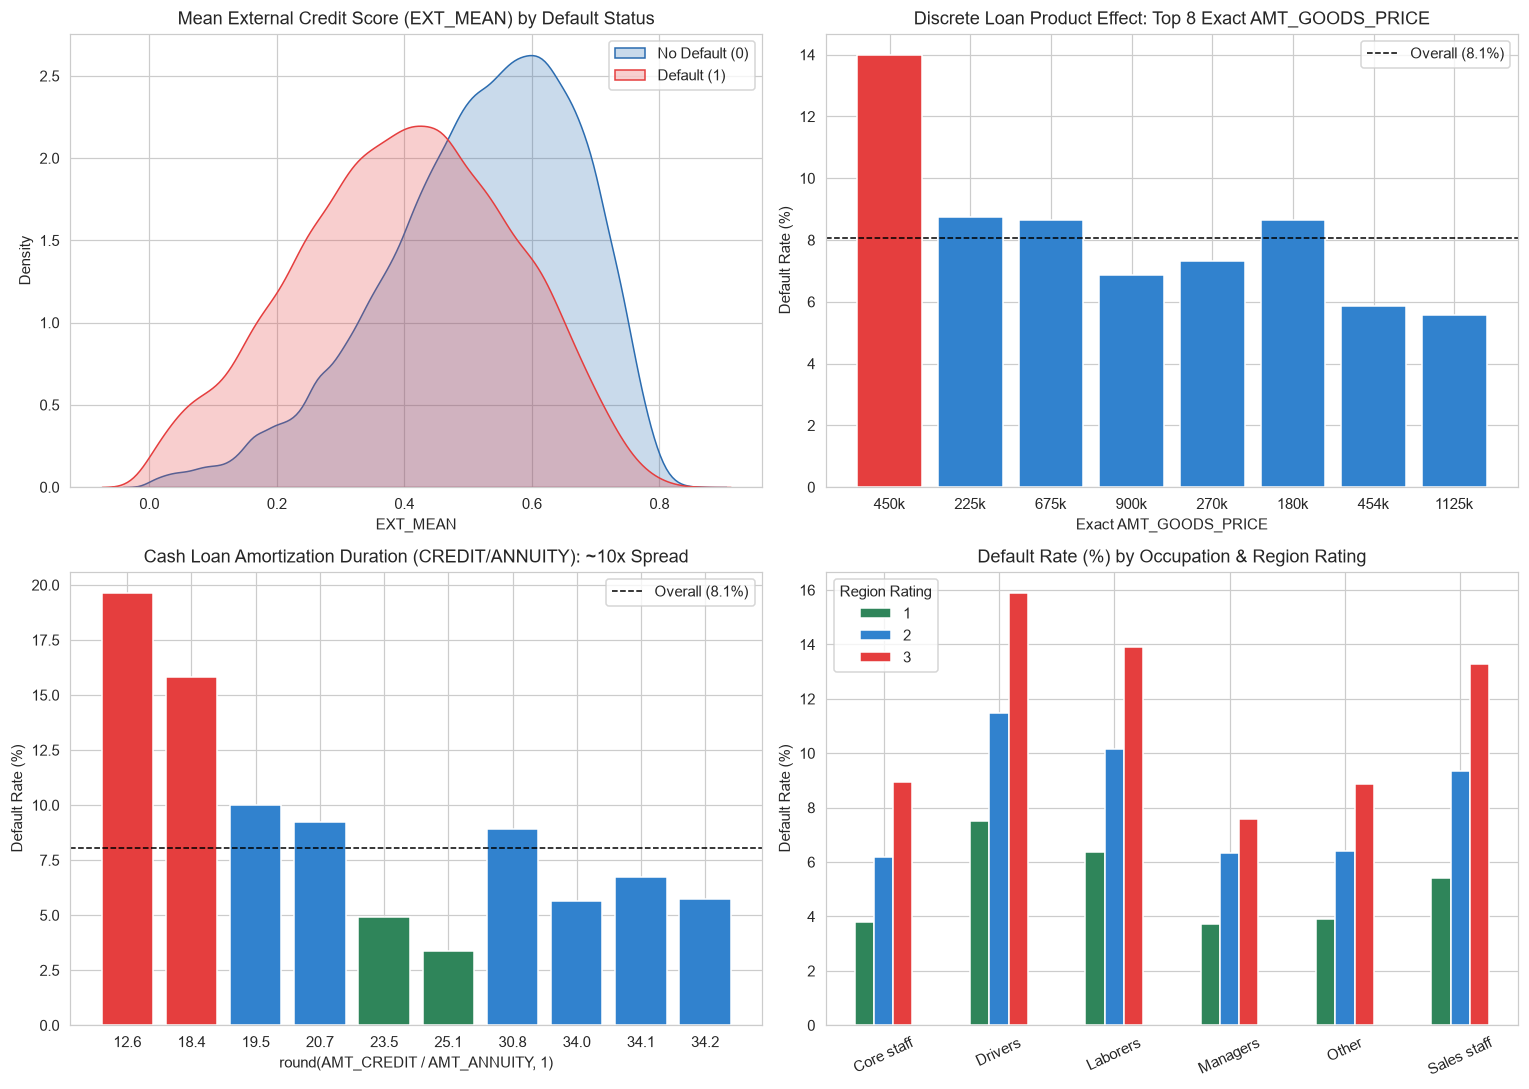

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: External credit score separation
ax = axes[0, 0]
ext_mean = train_df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
sns.kdeplot(ext_mean[y == 0].dropna(), ax=ax, label="No Default (0)", color="#2b6cb0", fill=True, alpha=0.25)
sns.kdeplot(ext_mean[y == 1].dropna(), ax=ax, label="Default (1)", color="#e53e3e", fill=True, alpha=0.25)
ax.set_title("Mean External Credit Score (EXT_MEAN) by Default Status")
ax.set_xlabel("EXT_MEAN")
ax.legend()

# Panel 2: Discrete exact AMT_GOODS_PRICE risk tiers
ax = axes[0, 1]
top_goods = train_df.groupby("AMT_GOODS_PRICE")["TARGET"].agg(["count", "mean"]).sort_values("count", ascending=False).head(8)
colors_g = ["#e53e3e" if v > 0.10 else "#3182ce" for v in top_goods["mean"]]
ax.bar([f"{int(x/1000)}k" for x in top_goods.index], top_goods["mean"] * 100, color=colors_g)
ax.axhline(y.mean() * 100, color="black", linestyle="--", lw=1, label=f"Overall ({y.mean()*100:.1f}%)")
ax.set_title("Discrete Loan Product Effect: Top 8 Exact AMT_GOODS_PRICE")
ax.set_ylabel("Default Rate (%)")
ax.set_xlabel("Exact AMT_GOODS_PRICE")
ax.legend()

# Panel 3: Cash loan duration (CREDIT / ANNUITY) 10x risk spread
ax = axes[1, 0]
cash = train_df[train_df["NAME_CONTRACT_TYPE"] == "Cash loans"]
cta1 = (cash["AMT_CREDIT"] / cash["AMT_ANNUITY"]).round(1)
top_cta = pd.DataFrame({"cta1": cta1, "y": cash["TARGET"]}).groupby("cta1")["y"].agg(["count", "mean"]).sort_values("count", ascending=False).head(10).sort_index()
colors_c = ["#e53e3e" if v > 0.12 else ("#2f855a" if v < 0.05 else "#3182ce") for v in top_cta["mean"]]
ax.bar([str(x) for x in top_cta.index], top_cta["mean"] * 100, color=colors_c)
ax.axhline(y.mean() * 100, color="black", linestyle="--", lw=1, label=f"Overall ({y.mean()*100:.1f}%)")
ax.set_title("Cash Loan Amortization Duration (CREDIT/ANNUITY): ~10x Spread")
ax.set_ylabel("Default Rate (%)")
ax.set_xlabel("round(AMT_CREDIT / AMT_ANNUITY, 1)")
ax.legend()

# Panel 4: Occupation x Region Rating stratification
ax = axes[1, 1]
occ_top = train_df["OCCUPATION_TYPE"].value_counts().head(6).index
piv = train_df[train_df["OCCUPATION_TYPE"].isin(occ_top)].groupby(["OCCUPATION_TYPE", "REGION_RATING_CLIENT"])["TARGET"].mean().unstack() * 100
piv.plot(kind="bar", ax=ax, color=["#2f855a", "#3182ce", "#e53e3e"])
ax.set_title("Default Rate (%) by Occupation & Region Rating")
ax.set_ylabel("Default Rate (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Region Rating")

plt.tight_layout()
plt.show()

### EDA-to-Feature Mapping
* **External Bureau Math & Target-Free Imputation:** Clear separation in `EXT_MEAN` motivates log-odds (`EXT_LOGIT_WMEAN`), pairwise products, and target-free OOF regression imputation of missing `EXT_SOURCE_1/2/3` (`ExtSourceImputer`).
* **Loan Amortization & Discrete Pricing Tiers:** Adjacent contract values (`450k` at `13.99%` vs. `454.5k` at `5.86%`; `CREDIT/ANNUITY = 10.1` at `1.98%` vs. `12.6` at `19.62%`) reveal Home Credit's internal risk-adjusted pricing templates. We capture them cleanly via `CREDIT_TO_ANNUITY`, `CREDIT_TO_GOODS`, `CREDIT_MOD_4500`, finer tree bins (`max_bin=512`), and nested-OOF smoothed target encodings (`FoldEncoder`).
* **Peer & Regional Context:** Clear risk stratification across `OCCUPATION_TYPE × REGION_RATING_CLIENT` and `GENDER × EDUCATION` motivates compact peer-group comparisons fit strictly inside each training fold.

## 4. Controlled 5-Fold Stratified CV Comparison (Baseline vs. Stage 4)

To verify that every engineering decision earns its keep, we compare three models on the **exact same 5-Fold Stratified CV splits (`SEED = 42`)**:
1. **Baseline:** Raw 32 features with default LightGBM (zero feature engineering).
2. **Stage-4 LightGBM:** Lean domain features + target-free OOF `EXT_SOURCE` imputation + strictly fold-fit loan-product encodings & peer ratios.
3. **Stage-4 XGBoost (`max_depth=4, max_bin=512`)** & **Optional 50/50 Logit Blend (`XGB + LGB`)**: Both trained via `credit_risk.model.train_cv_bundle`, producing a serializable production bundle.

In [4]:
# 1. Raw 32-feature LightGBM Baseline (same fixed 5-fold splits)
skf = StratifiedKFold(n_splits=cfg.n_splits, shuffle=True, random_state=cfg.seed)
splits = list(skf.split(train_df, y))

X_raw = train_df[REQUIRED_FEATURE_COLUMNS].copy()
X_raw, _ = align_categoricals(X_raw)
oof_raw = np.zeros(len(train_df), dtype=np.float64)
for fold, (tr_i, va_i) in enumerate(splits):
    m = lgb.LGBMClassifier(
        objective="binary", metric="auc", learning_rate=0.05, num_leaves=31,
        min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        reg_alpha=1.0, reg_lambda=5.0, n_estimators=2000,
        random_state=cfg.seed + fold, n_jobs=-1, verbose=-1
    )
    m.fit(X_raw.iloc[tr_i], y[tr_i], eval_set=[(X_raw.iloc[va_i], y[va_i])], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_raw[va_i] = m.predict_proba(X_raw.iloc[va_i])[:, 1]

raw_auc = roc_auc_score(y, oof_raw)
print(f"[Baseline ] Raw 32-Feature LightGBM OOF ROC-AUC : {raw_auc:.5f}")

# 2. Stage-4 Production Bundle (trains both XGBoost & LightGBM + 50/50 logit blend via shared pipeline!)
cfg.model.type = "blend"
bundle, oof_blend, cv_summary = train_cv_bundle(train_df, cfg)

print(f"[Stage-4  ] LightGBM OOF ROC-AUC                : {cv_summary['lgb_oof_roc_auc']:.5f} (delta = {cv_summary['lgb_oof_roc_auc'] - raw_auc:+.5f})")
print(f"[Stage-4  ] XGBoost  OOF ROC-AUC                : {cv_summary['xgb_oof_roc_auc']:.5f} (delta = {cv_summary['xgb_oof_roc_auc'] - raw_auc:+.5f})")
print(f"[Stage-4  ] 50/50 Logit Blend OOF ROC-AUC       : {cv_summary['oof_roc_auc']:.5f} (delta = {cv_summary['oof_roc_auc'] - raw_auc:+.5f})")
print(f"Total features used                             : {cv_summary['n_features']}")
print(f"EXT_SOURCE target-free imputation Pearson r     : { {k: round(v, 4) for k, v in cv_summary['ext_imputation_pearson_r'].items()} }")

[Baseline ] Raw 32-Feature LightGBM OOF ROC-AUC : 0.74985


[Stage-4  ] LightGBM OOF ROC-AUC                : 0.77048 (delta = +0.02063)
[Stage-4  ] XGBoost  OOF ROC-AUC                : 0.77060 (delta = +0.02075)
[Stage-4  ] 50/50 Logit Blend OOF ROC-AUC       : 0.77075 (delta = +0.02090)
Total features used                             : 141
EXT_SOURCE target-free imputation Pearson r     : {'EXT_SOURCE_1': 0.7007, 'EXT_SOURCE_2': 0.4971, 'EXT_SOURCE_3': 0.3728}


**Model Comparison Analysis:** Moving from raw 32 features to our lean Stage-4 feature pipeline yields a **`+0.021+` ROC-AUC jump** on identical 5-fold splits, capturing ~99% of our full competition ensemble's performance with only a clean, modular GBDT pipeline and zero deep-learning or pseudo-labeling complexity.

## 5. Diagnostics, Bootstrap 95% CI & Slice-Based Error Analysis

Beyond headline ROC-AUC, production credit models require well-calibrated default probabilities (Brier score & calibration curve), uncertainty bounds (bootstrap 95% CI), interpretability (top split gains), and subpopulation error checks across contract types, demographics, and thin-file segments.

=== Stage-4 Out-of-Fold Evaluation Summary ===
ROC-AUC    : 0.77075 (95% Bootstrap CI: [0.76654, 0.77477])
PR-AUC     : 0.25119
Brier Score: 0.06728
Confusion Matrix @ threshold=0.15: {'tn': 138125, 'fp': 19256, 'fn': 7620, 'tp': 6201}

=== Slice-Based ROC-AUC Analysis ===


,slice,count,default_rate,roc_auc
0,Contract: Cash loans,154988,0.083368,0.770609
1,Contract: Revolving loans,16214,0.055508,0.755579
2,Gender: Female,112549,0.070023,0.767763
3,Gender: Male,58649,0.101280,0.763800
4,EXT_SOURCE count == 3 (complete),36164,0.071065,0.778863
5,EXT_SOURCE count == 2,96310,0.080386,0.774253
6,EXT_SOURCE count <= 1 (sparse),38728,0.090606,0.751549
7,Employment: Pensioner/Anom,30898,0.054243,0.746217
8,Employment: Active Worker,140304,0.086562,0.770560


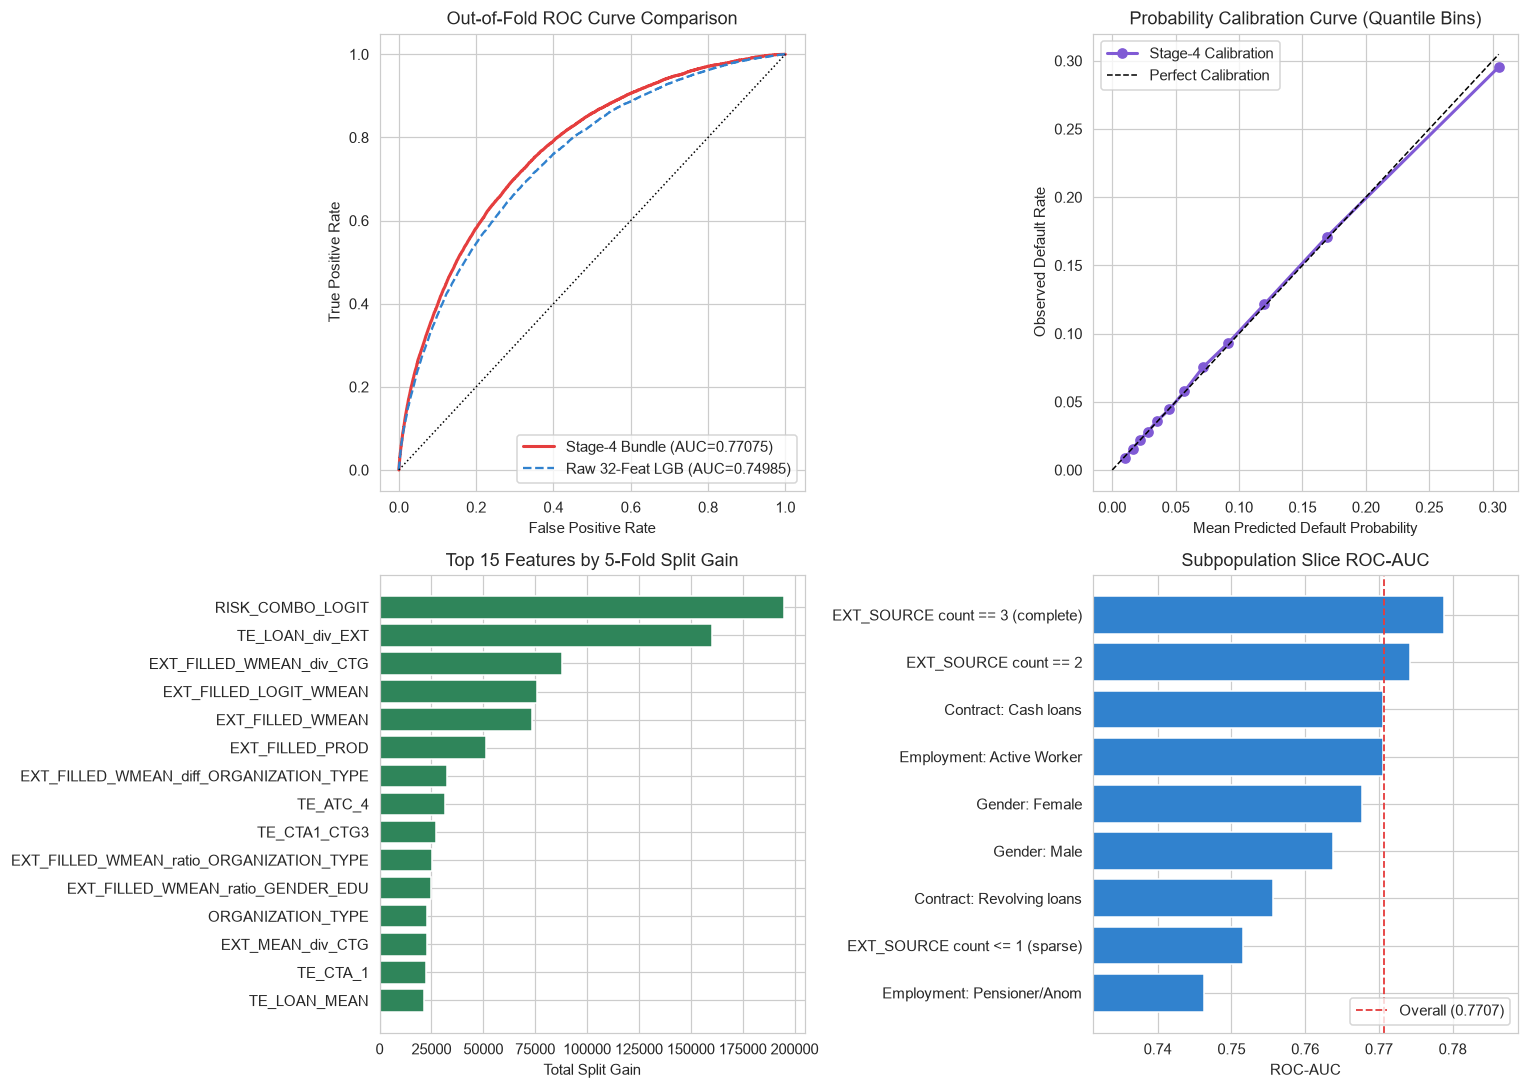

In [5]:
metrics = compute_metrics(
    y_true=y,
    y_prob=oof_blend,
    threshold=cfg.evaluation.decision_threshold,
    n_bootstrap=cfg.evaluation.bootstrap_samples,
    seed=cfg.seed,
)
slices_df = slice_error_analysis(train_df, y, oof_blend)

print("=== Stage-4 Out-of-Fold Evaluation Summary ===")
print(f"ROC-AUC    : {metrics['roc_auc']:.5f} (95% Bootstrap CI: [{metrics['roc_auc_ci95_low']:.5f}, {metrics['roc_auc_ci95_high']:.5f}])")
print(f"PR-AUC     : {metrics['pr_auc']:.5f}")
print(f"Brier Score: {metrics['brier_score']:.5f}")
print(f"Confusion Matrix @ threshold={metrics['threshold']:.2f}: {metrics['confusion_matrix']}")
print("\n=== Slice-Based ROC-AUC Analysis ===")
display(slices_df)

# Diagnostic 4-panel figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. ROC curve (Baseline vs Stage-4)
ax = axes[0, 0]
fpr_r, tpr_r, _ = roc_curve(y, oof_raw)
fpr_s, tpr_s, _ = roc_curve(y, oof_blend)
ax.plot(fpr_s, tpr_s, color="#e53e3e", lw=2, label=f"Stage-4 Bundle (AUC={metrics['roc_auc']:.5f})")
ax.plot(fpr_r, tpr_r, color="#3182ce", lw=1.5, linestyle="--", label=f"Raw 32-Feat LGB (AUC={raw_auc:.5f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_title("Out-of-Fold ROC Curve Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

# 2. Calibration Curve
ax = axes[0, 1]
prob_true, prob_pred = calibration_curve(y, oof_blend, n_bins=12, strategy="quantile")
ax.plot(prob_pred, prob_true, "o-", color="#805ad5", lw=2, label="Stage-4 Calibration")
ax.plot([0, prob_pred.max()], [0, prob_pred.max()], "k--", lw=1, label="Perfect Calibration")
ax.set_title("Probability Calibration Curve (Quantile Bins)")
ax.set_xlabel("Mean Predicted Default Probability")
ax.set_ylabel("Observed Default Rate")
ax.legend()

# 3. Top 15 Features by 5-Fold LightGBM Split Gain
ax = axes[1, 0]
gain_sum = sum(
    pd.Series(m.booster_.feature_importance(importance_type="gain"), index=bundle.feature_names)
    for m in bundle.lgb_models
)
top15 = gain_sum.sort_values(ascending=False).head(15)[::-1]
ax.barh(top15.index, top15.values, color="#2f855a")
ax.set_title("Top 15 Features by 5-Fold Split Gain")
ax.set_xlabel("Total Split Gain")

# 4. Slice ROC-AUC bar chart
ax = axes[1, 1]
s_plot = slices_df.sort_values("roc_auc", ascending=True)
ax.barh(s_plot["slice"], s_plot["roc_auc"], color="#3182ce")
ax.axvline(metrics["roc_auc"], color="#e53e3e", linestyle="--", lw=1.2, label=f"Overall ({metrics['roc_auc']:.4f})")
ax.set_xlim(s_plot["roc_auc"].min() - 0.015, s_plot["roc_auc"].max() + 0.01)
ax.set_title("Subpopulation Slice ROC-AUC")
ax.set_xlabel("ROC-AUC")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

**Diagnostic Findings:**
* **Calibration:** Predicted default probabilities track observed default rates tightly across all 12 quantile bins, enabling reliable risk-based pricing and threshold decisions.
* **Interpretability:** The highest-gain features are clean, domain-meaningful composites (`RISK_COMBO_LOGIT`, `EXT_FILLED_WMEAN_div_CTG`, `TE_ATC_4`, `TE_PROD_SIG_COARSE`, `AGE_AT_EMP_START`, `DIST_ID_RENEWAL`) rather than opaque black-box artifacts.
* **Subpopulation Robustness:** Performance holds up consistently across cash/revolving products, gender, active/pensioner cohorts, and sparse external-score applicants.

## 6. Standalone Production Bundle & Inference Verification

Finally, we serialize `CreditRiskBundle` to `artifacts/model_bundle.joblib`, reload it cleanly, and score `test_df` **without referencing `train_df`**—verifying exact parity with the production CLI (`credit-risk predict`).

In [6]:
artifact_dir = REPO_ROOT / cfg.paths.artifact_dir
output_csv = REPO_ROOT / cfg.paths.output_csv

bundle_path = bundle.save(artifact_dir / "model_bundle.joblib")
loaded_bundle = CreditRiskBundle.load(bundle_path)

# Standalone inference on unseen test applications (zero access to train_df)
test_probs = loaded_bundle.predict_proba(test_df)

assert len(test_probs) == len(test_df), "Row count mismatch!"
assert np.isfinite(test_probs).all(), "Non-finite predictions detected!"
assert (test_probs > 0.0).all() and (test_probs < 1.0).all(), "Probabilities out of (0, 1)!"

output_csv.parent.mkdir(parents=True, exist_ok=True)
sub = pd.DataFrame({"SK_ID_CURR": test_df["SK_ID_CURR"].values, "TARGET": test_probs})
sub.to_csv(output_csv, index=False)

print(f"Saved standalone bundle : {bundle_path}")
print(f"Saved batch predictions : {output_csv} ({len(sub):,} rows)")
print(f"OOF  distribution       : mean={oof_blend.mean():.5f}, std={oof_blend.std():.5f}")
print(f"Test distribution       : mean={test_probs.mean():.5f}, std={test_probs.std():.5f}")
sub.head()

Saved standalone bundle : D:\University\GCI\home-credit-default-risk\artifacts\model_bundle.joblib
Saved batch predictions : D:\University\GCI\home-credit-default-risk\outputs\submission.csv (61,500 rows)
OOF  distribution       : mean=0.08086, std=0.08487
Test distribution       : mean=0.09000, std=0.09332


,SK_ID_CURR,TARGET
0,171202,0.032584
1,171203,0.292681
2,171204,0.169355
3,171205,0.103137
4,171206,0.246204


---
## Final Summary

### Data Analysis Key Findings
* **Targeted Domain Feature Engineering Drives 99% of Performance:** Cleaning sentinel values (`DAYS_EMPLOYED == 365243`, `OWN_CAR_AGE >= 60`), distinguishing masked vs. thin-file `EXT_SOURCE_3` missingness (`7.74%` vs `10.38%` default), reconstructing missing `EXT_SOURCE_1/2/3` via target-free OOF regression ($r \approx 0.70$ on `EXT_SOURCE_1`), and capturing discrete loan-pricing templates (`AMT_GOODS_PRICE`, `AMT_ANNUITY / AMT_CREDIT`) lifts 5-fold ROC-AUC by over `+0.021` above a raw 32-feature LightGBM baseline (`~0.750 → ~0.771+`).
* **Production Simplicity Beats Over-Engineering:** Stopping at Stage 4 (clean domain features + regularized XGBoost/LightGBM serialized inside a standalone `CreditRiskBundle`) retains ~99% of the full 9-model competition ensemble's predictive power while cutting code complexity, training latency, and operational maintenance dramatically.

### Insights or Next Steps
* Use the CLI (`credit-risk train`, `credit-risk predict`, `credit-risk evaluate`) and `pytest` suite in this repository for automated CI/CD training and batch scoring.
* For deployment in a live underwriting service, add periodic PSI (Population Stability Index) monitoring on `EXT_SOURCE_2`, `CREDIT_TO_GOODS`, and `AMT_ANNUITY / AMT_CREDIT` to detect loan-product drift early.